# Diferencias divididas

## Primero importamos la librerias a utilizar

In [5]:
from sympy import *
import pandas as pd
from tabulate import tabulate

## Pedimos al usuario que ingrese los nodos a utilizar y los guardamos en una lista

In [2]:
while True:
    try:
        num_nodos=int(input("Ingrese el número de nodos a utilizar: "))
        break
    except ValueError:
        print("Ingrese un número entero")
vector_nodos=[]
for i in range(num_nodos):
    while True:
        try:
            if i==range(num_nodos):
                vector_nodos.append(float(input(f"Ingrese el nodo x_{i}: ")))
                break
            else:
                vector_nodos.append(float(input(f"Ingrese el nodo x_{i}: ")))
                vector_nodos.append("")
                break
        except:
            print("El nodo debe ser un número real")

Ingrese el número de nodos a utilizar:  5
Ingrese el nodo x_0:  1
Ingrese el nodo x_1:  1.3
Ingrese el nodo x_2:  1.6
Ingrese el nodo x_3:  1.9
Ingrese el nodo x_4:  2.2


## Hacemos una matriz que contendrá los $f(x_i)$ y efectuamos el algoritmo

In [3]:
#Generemos la matriz con sus vectores y una lista que se el conjunto que contiene el número de nodos desde n hasta 1
matriz=[]
b=[]
for i in range(num_nodos):
    b.append(num_nodos-i)
    matriz.append([])
#Hagamos nuestra matriz
for i in range(num_nodos):
    if i==0: 
        for j in range(b[i]):
            matriz[i].append(float(input(f"Ingrese los f(x_{j}): ")))
    if i>0:
        for j in range(b[i]):    
            matriz[i].append((matriz[i-1][j+1]-matriz[i-1][j])/(vector_nodos[2*(j+i)]-vector_nodos[2*j]))     

Ingrese los f(x_0):  0.7651977
Ingrese los f(x_1):  0.6200860
Ingrese los f(x_2):  0.4554022
Ingrese los f(x_3):  0.2818186
Ingrese los f(x_4):  0.1103623


## Elaboremos la tabla

In [7]:
matrizf=[]
cabecera=[]
for i in range(num_nodos+1):
    if i==0:
        cabecera.append("x_i")
    elif i==1:
        cabecera.append("f(x_i): ")
    else:
        cabecera.append(f"{i-1}as dif. divididas")
matrizf.append(vector_nodos)
for i in range(num_nodos):
    matrizf.append([])
for i in range(num_nodos):
    for k in range(i):
        matrizf[i+1].append("")
for i in range(num_nodos):
    for j in range(b[i]):
        if j==range(b[i]):
            matrizf[i].append(matriz[i][j])
        else:
            matrizf[i+1].append(matriz[i][j])
            matrizf[i+1].append("")
df = pd.DataFrame(matrizf).T
print(tabulate(df, headers=cabecera, tablefmt='fancy_grid', showindex=False))


╒═══════╤════════════╤══════════════════════╤══════════════════════╤══════════════════════╤══════════════════════╕
│   x_i │   f(x_i):  │   1as dif. divididas │   2as dif. divididas │   3as dif. divididas │   4as dif. divididas │
╞═══════╪════════════╪══════════════════════╪══════════════════════╪══════════════════════╪══════════════════════╡
│   1   │   0.765198 │                      │                      │                      │                      │
├───────┼────────────┼──────────────────────┼──────────────────────┼──────────────────────┼──────────────────────┤
│       │            │            -0.483706 │                      │                      │                      │
├───────┼────────────┼──────────────────────┼──────────────────────┼──────────────────────┼──────────────────────┤
│   1.3 │   0.620086 │                      │           -0.108734  │                      │                      │
├───────┼────────────┼──────────────────────┼──────────────────────┼────────────

 ## Hagamos un vector con los $a_i$ y definamos los símbolos

In [13]:
x=symbols('x')
P=Function('P')
ai=[]
for i in range(num_nodos):
    ai.append(matriz[i][0])
#Limpiemos vector_nodos
vn=[]
for i in range(len(vector_nodos)):
    if type(vector_nodos[i]) is float:
        vn.append(vector_nodos[i])
#definimos la P del polinonio y lo armamos
P = 0
for k in range(num_nodos):
    P+=ai[k]*prod([x - vn[j] for j in range(k)])
P

-0.483705666666666*x + 0.00182510288066044*(x - 1.9)*(x - 1.6)*(x - 1.3)*(x - 1.0) + 0.0658783950617283*(x - 1.6)*(x - 1.3)*(x - 1.0) - 0.108733888888889*(x - 1.3)*(x - 1.0) + 1.24890336666667

## Simplificamos P y generamos la gráfica

In [9]:
simplify(P)

0.00182510288066044*x**4 + 0.0552927983538978*x**3 - 0.343046604938247*x**2 + 0.0733913477366034*x + 0.977735055967085

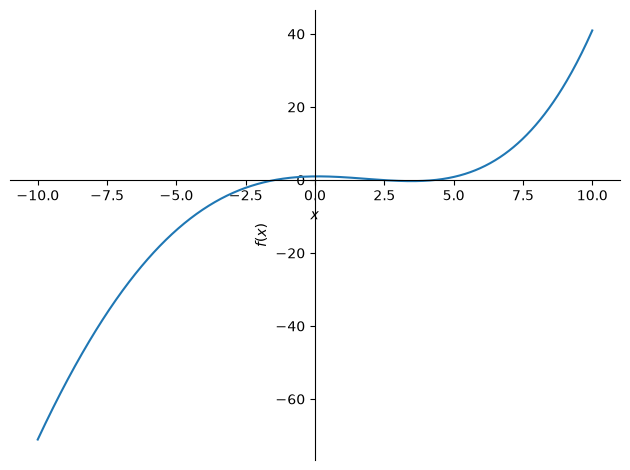

In [11]:
plotting.plot(P)